<a href="https://colab.research.google.com/github/christinafan-cell/MSSP607/blob/main/Assignment_1_PythonCode(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Academic Performance of Engineering Students

This notebook uses descriptive statistics and basic charts to examine parental education, socioeconomic stratum, gender, and academic performance. The global assessment score (`G_SC`) is the main outcome.

## 1. Import libraries and upload the data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

Saving data_academic_performance (1).xlsx to data_academic_performance (1).xlsx


## 2. Read the student records

The workbook contains several sheets. This cell reads the student data sheet, prints the number of rows and columns, and displays the first five records. The original data are kept in `raw`.

In [ ]:
raw = pd.read_excel(file_name, sheet_name="SABER11_SABERPRO")
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (12411, 45)


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


## 3. Check data types and missing values

This cell checks how each variable is stored and counts blank values. A zero in a background category may represent an undocumented code even when it is not counted as a missing value.

In [ ]:
raw.info()
print("Missing values by column:")
print(raw.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12411 entries, 0 to 12410
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COD_S11           12411 non-null  object 
 1   GENDER            12411 non-null  object 
 2   EDU_FATHER        12411 non-null  object 
 3   EDU_MOTHER        12411 non-null  object 
 4   OCC_FATHER        12411 non-null  object 
 5   OCC_MOTHER        12411 non-null  object 
 6   STRATUM           12411 non-null  object 
 7   SISBEN            12411 non-null  object 
 8   PEOPLE_HOUSE      12411 non-null  object 
 9   Unnamed: 9        0 non-null      float64
 10  INTERNET          12411 non-null  object 
 11  TV                12411 non-null  object 
 12  COMPUTER          12411 non-null  object 
 13  WASHING_MCH       12411 non-null  object 
 14  MIC_OVEN          12411 non-null  object 
 15  CAR               12411 non-null  object 
 16  DVD               12411 non-null  object

## 4. Make a simple working copy

This cell removes the empty column and cleans spaces in the six background variables used for grouping. In these variables only, the undocumented zero code is labelled "Unspecified". "Not sure" and "Ninguno" remain separate. Assessment scores are not changed, and no records are deleted.

In [ ]:
df = raw.copy()
df = df.drop(columns=["Unnamed: 9"])

groups = ["GENDER", "EDU_FATHER", "EDU_MOTHER",
          "STRATUM", "SISBEN", "ACADEMIC_PROGRAM"]

for column in groups:
    df[column] = df[column].fillna("Missing")
    df[column] = df[column].astype(str).str.strip()
    df[column] = df[column].replace({"0": "Unspecified", "0.0": "Unspecified"})

print("Rows and columns after cleaning:", df.shape)
print(df[groups].head())

Rows and columns after cleaning: (12411, 44)
  GENDER                         EDU_FATHER                        EDU_MOTHER  \
0      F  Incomplete Professional Education  Complete technique or technology   
1      F                 Complete Secundary   Complete professional education   
2      M                           Not sure                          Not sure   
3      F                           Not sure                          Not sure   
4      M    Complete professional education   Complete professional education   

     STRATUM                              SISBEN        ACADEMIC_PROGRAM  
0  Stratum 4  It is not classified by the SISBEN  INDUSTRIAL ENGINEERING  
1  Stratum 5  It is not classified by the SISBEN  INDUSTRIAL ENGINEERING  
2  Stratum 2                             Level 2  ELECTRONIC ENGINEERING  
3  Stratum 2  It is not classified by the SISBEN  INDUSTRIAL ENGINEERING  
4  Stratum 4  It is not classified by the SISBEN  INDUSTRIAL ENGINEERING  


## 5. Check duplicate records and identifiers

This cell checks complete duplicate rows and repeated test identifiers. A repeated identifier is not necessarily a completely duplicated row. The data contain 16 repeated professional-test identifiers involving 32 records. These records are retained for the initial descriptive analysis and must be investigated before inferential analysis.

In [ ]:
print("Complete duplicate rows:", df.duplicated().sum())
print("Repeated secondary-school IDs:", df["COD_S11"].duplicated().sum())
print("Repeated professional-test IDs:", df["Cod_SPro"].duplicated().sum())

repeated = df[df["Cod_SPro"].duplicated(keep=False)]
print("Records involved:", len(repeated))
repeated[["COD_S11", "Cod_SPro", "GENDER", "G_SC"]].sort_values("Cod_SPro")

Complete duplicate rows: 0
Repeated secondary-school IDs: 0
Repeated professional-test IDs: 16
Records involved: 32


,COD_S11,Cod_SPro,GENDER,G_SC
6524,SB11201320110284,EK201830012603,M,168
2259,SB11201220313289,EK201830012603,M,168
8035,SB11201320225581,EK201830013197,F,118
604,SB11201220043502,EK201830013197,F,118
2023,SB11201220288842,EK201830017763,M,150
4289,SB11201310002204,EK201830017763,M,150
4648,SB11201310072215,EK201830022057,M,172
2659,SB11201220340907,EK201830022057,M,172
2463,SB11201220326795,EK201830030238,M,162
8250,SB11201320242054,EK201830030238,M,162


## 6. Summarize assessment scores

The table shows the count, mean, standard deviation, minimum, quartiles, and maximum for each assessment variable. The 50% column is the median.

In [ ]:
scores = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11",
          "QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO",
          "FEP_PRO", "G_SC"]

overall = df[scores].describe().T
overall.round(2)

,count,mean,std,min,25%,50%,75%,max
MAT_S11,12411.0,64.32,11.87,26.0,56.0,64.0,72.0,100.0
CR_S11,12411.0,60.78,10.03,24.0,54.0,61.0,67.0,100.0
CC_S11,12411.0,60.71,10.12,0.0,54.0,60.0,67.0,100.0
BIO_S11,12411.0,63.95,11.16,11.0,56.0,64.0,71.0,100.0
ENG_S11,12411.0,61.80,14.30,26.0,50.0,59.0,72.0,100.0
QR_PRO,12411.0,77.42,22.67,1.0,65.0,85.0,96.0,100.0
CR_PRO,12411.0,62.20,27.67,1.0,42.0,67.0,86.0,100.0
CC_PRO,12411.0,59.19,28.99,1.0,36.0,65.0,85.0,100.0
ENG_PRO,12411.0,67.50,25.50,1.0,51.0,74.0,88.0,100.0
WC_PRO,12411.0,53.70,30.00,0.0,28.0,56.0,80.0,100.0


## 7. Calculate additional descriptive measures

The median describes the centre of the scores. The interquartile range (IQR) measures the spread of the middle 50% of values. Variance and skewness provide additional information about variation and asymmetry, following the descriptive-statistics reference.

In [ ]:
extra = pd.DataFrame()
extra["Median"] = df[scores].median()
extra["Variance"] = df[scores].var()
extra["IQR"] = df[scores].quantile(0.75) - df[scores].quantile(0.25)
extra["Skewness"] = df[scores].skew()
extra.round(2)

,Median,Variance,IQR,Skewness
MAT_S11,64.0,140.98,16.0,0.40
CR_S11,61.0,100.52,13.0,0.21
CC_S11,60.0,102.43,13.0,0.35
BIO_S11,64.0,124.48,15.0,0.30
ENG_S11,59.0,204.43,22.0,0.61
QR_PRO,85.0,514.09,31.0,-1.18
CR_PRO,67.0,765.44,44.0,-0.52
CC_PRO,65.0,840.53,49.0,-0.42
ENG_PRO,74.0,650.00,37.0,-0.80
WC_PRO,56.0,900.10,52.0,-0.18


## 8. Count the background categories

Frequency tables show how many records are in each group and their percentage of the full dataset. Check unequal group sizes and unspecified categories before comparing performance. The short loop repeats the same calculation for each background variable.

In [ ]:
for column in groups:
    print(column)
    frequency = pd.DataFrame()
    frequency["Count"] = df[column].value_counts()
    frequency["Percent"] = df[column].value_counts(normalize=True) * 100
    display(frequency.round(2))

GENDER


,Count,Percent
GENDER,,
M,7368,59.37
F,5043,40.63


EDU_FATHER


,Count,Percent
EDU_FATHER,,
Complete professional education,3016,24.30
Complete Secundary,2843,22.91
Complete technique or technology,1194,9.62
Incomplete Secundary,1091,8.79
Postgraduate education,1085,8.74
Complete primary,824,6.64
Incomplete primary,735,5.92
Incomplete Professional Education,425,3.42
Not sure,407,3.28


EDU_MOTHER


,Count,Percent
EDU_MOTHER,,
Complete Secundary,3106,25.03
Complete professional education,3059,24.65
Complete technique or technology,1495,12.05
Incomplete Secundary,1056,8.51
Postgraduate education,997,8.03
Complete primary,713,5.74
Incomplete primary,541,4.36
Incomplete Professional Education,502,4.04
Unspecified,388,3.13


... (2 outputs left out)

SISBEN


,Count,Percent
SISBEN,,
It is not classified by the SISBEN,7534,60.70
Level 2,2120,17.08
Level 1,2057,16.57
Level 3,583,4.70
Esta clasificada en otro Level del SISBEN,96,0.77
Unspecified,21,0.17


ACADEMIC_PROGRAM


,Count,Percent
ACADEMIC_PROGRAM,,
INDUSTRIAL ENGINEERING,5318,42.85
CIVIL ENGINEERING,3320,26.75
MECHANICAL ENGINEERING,1135,9.15
CHEMICAL ENGINEERING,1000,8.06
ELECTRONIC ENGINEERING,849,6.84
ELECTRIC ENGINEERING,278,2.24
MECHATRONICS ENGINEERING,82,0.66
CATASTRAL ENGINEERING AND GEODESY,78,0.63
PRODUCTION ENGINEERING,60,0.48


## 9. Plot the global score distribution

The histogram shows the distribution of global assessment scores. The dashed line marks the mean. Look at the centre, spread, and shape of the distribution rather than judging performance from the mean alone.

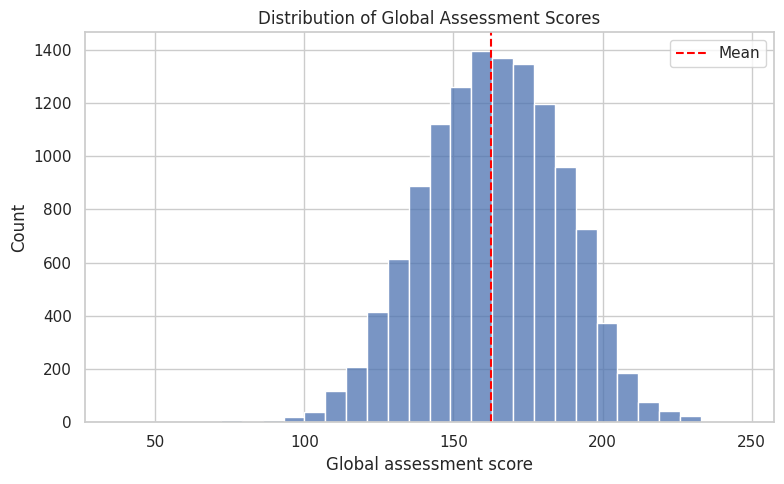

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G_SC", bins=30)
plt.axvline(df["G_SC"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Distribution of Global Assessment Scores")
plt.xlabel("Global assessment score")
plt.legend()
plt.tight_layout()
plt.savefig("global_histogram.png", dpi=300)
plt.show()

## 10. Inspect potential outliers

The boxplot shows the median, quartiles, and potential outliers in global scores.

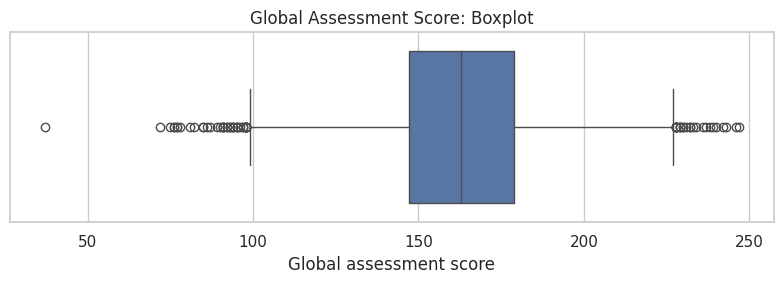

In [ ]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=df, x="G_SC")
plt.title("Global Assessment Score: Boxplot")
plt.xlabel("Global assessment score")
plt.tight_layout()
plt.savefig("global_boxplot.png", dpi=300)
plt.show()

## 11. Compare scores by father's education

This table compares global scores across the father's education categories. Counts, means, medians, and standard deviations are reported. The final calculation compares postgraduate education with completed secondary education using unrounded means.

In [ ]:
father = df.groupby("EDU_FATHER")["G_SC"].agg(["count", "mean", "median", "std"])
display(father.round(2))

father_gap = father.loc["Postgraduate education", "mean"] - father.loc["Complete Secundary", "mean"]
print("Postgraduate minus completed secondary:", round(father_gap, 2), "points")

,count,mean,median,std
EDU_FATHER,,,,
Complete Secundary,2843,158.79,159.0,22.11
Complete primary,824,155.20,155.0,22.41
Complete professional education,3016,167.77,169.0,23.03
Complete technique or technology,1194,164.03,164.0,22.17
Incomplete Professional Education,425,166.92,168.0,22.69
Incomplete Secundary,1091,156.54,157.0,21.74
Incomplete primary,735,155.73,156.0,20.94
Incomplete technical or technological,277,162.10,162.0,21.88
Ninguno,123,156.63,159.0,23.19


Postgraduate minus completed secondary: 18.2 points


## 12. Compare scores by mother's education

This cell repeats the same comparison for the mother's education. Keeping the two parents separate makes the interpretation clear. The difference is descriptive and does not isolate education from other family characteristics.

In [ ]:
mother = df.groupby("EDU_MOTHER")["G_SC"].agg(["count", "mean", "median", "std"])
display(mother.round(2))

mother_gap = mother.loc["Postgraduate education", "mean"] - mother.loc["Complete Secundary", "mean"]
print("Postgraduate minus completed secondary:", round(mother_gap, 2), "points")

,count,mean,median,std
EDU_MOTHER,,,,
Complete Secundary,3106,158.47,159.0,21.95
Complete primary,713,155.34,155.0,22.01
Complete professional education,3059,168.85,170.0,22.98
Complete technique or technology,1495,163.24,163.0,21.94
Incomplete Professional Education,502,166.69,168.0,22.93
Incomplete Secundary,1056,155.67,156.0,21.93
Incomplete primary,541,154.85,155.0,21.64
Incomplete technical or technological,341,161.88,164.0,20.74
Ninguno,34,149.71,152.5,27.93


Postgraduate minus completed secondary: 17.17 points


## 13. Visualize parental education differences

The horizontal bar charts compare mean global scores across parental education categories. Both charts use the same score range. Categories are sorted by their observed means, not by an assumed educational ranking. Unspecified and uncertain responses are shown but are not education levels.

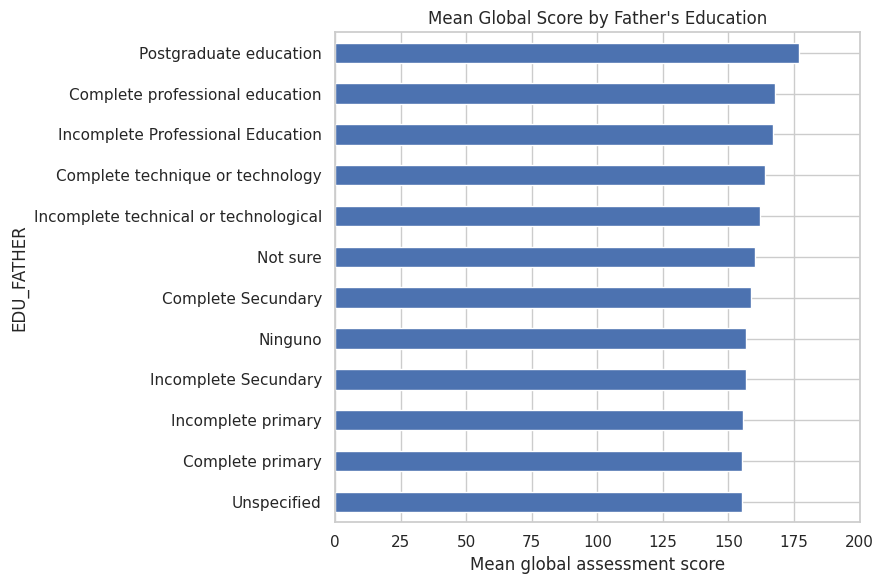

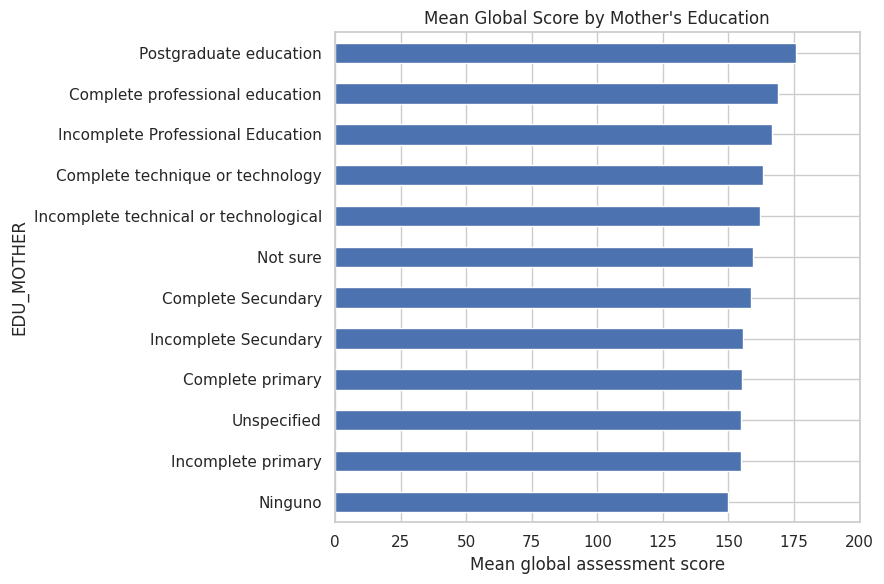

In [ ]:
father["mean"].sort_values().plot(kind="barh", figsize=(9, 6), xlim=(0, 200))
plt.title("Mean Global Score by Father's Education")
plt.xlabel("Mean global assessment score")
plt.tight_layout()
plt.savefig("father_education.png", dpi=300)
plt.show()

mother["mean"].sort_values().plot(kind="barh", figsize=(9, 6), xlim=(0, 200))
plt.title("Mean Global Score by Mother's Education")
plt.xlabel("Mean global assessment score")
plt.tight_layout()
plt.savefig("mother_education.png", dpi=300)
plt.show()

## 14. Compare socioeconomic strata

This cell compares global scores across socioeconomic strata and calculates the difference between Stratum 6 and Stratum 1. The unspecified category is retained in the table but is not interpreted as a socioeconomic level.

In [ ]:
stratum = df.groupby("STRATUM")["G_SC"].agg(["count", "mean", "median", "std"])
display(stratum.round(2))

stratum_gap = stratum.loc["Stratum 6", "mean"] - stratum.loc["Stratum 1", "mean"]
print("Stratum 6 minus Stratum 1:", round(stratum_gap, 2), "points")

,count,mean,median,std
STRATUM,,,,
Stratum 1,1709,152.35,152.0,21.94
Stratum 2,4029,158.20,158.0,22.28
Stratum 3,4045,163.82,164.0,21.69
Stratum 4,1578,172.00,174.0,21.47
Stratum 5,633,177.39,179.0,21.54
Stratum 6,403,181.51,184.0,21.88
Unspecified,14,154.00,152.5,21.32


Stratum 6 minus Stratum 1: 29.16 points


## 15. Visualize score distributions by stratum

Boxplots compare both the centre and spread of scores across the six reported strata.

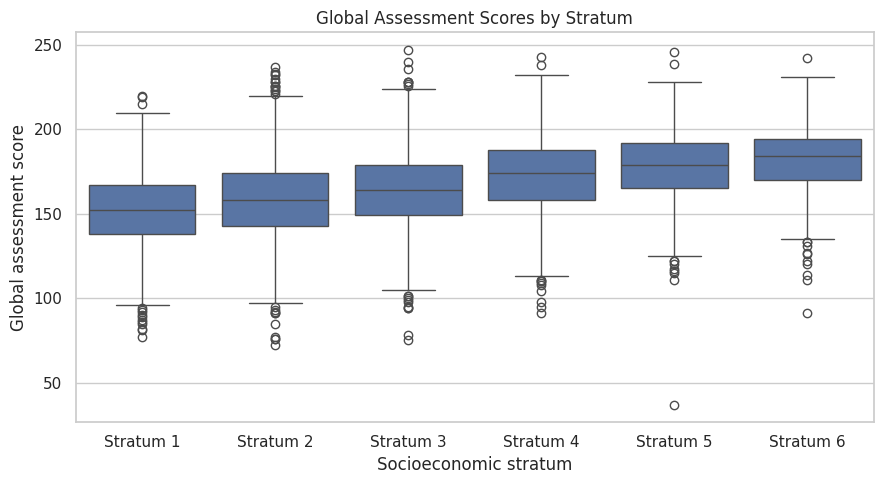

In [ ]:
stratum_order = ["Stratum 1", "Stratum 2", "Stratum 3",
                 "Stratum 4", "Stratum 5", "Stratum 6"]

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="STRATUM", y="G_SC", order=stratum_order)
plt.title("Global Assessment Scores by Stratum")
plt.xlabel("Socioeconomic stratum")
plt.ylabel("Global assessment score")
plt.tight_layout()
plt.savefig("stratum_boxplot.png", dpi=300)
plt.show()

## 16. Compare global scores by gender

This cell summarizes global scores for female and male students and calculates the male-minus-female mean difference. The standard deviations help put the difference between group means in context.

In [ ]:
gender = df.groupby("GENDER")["G_SC"].agg(["count", "mean", "median", "std"])
display(gender.round(2))

gender_gap = gender.loc["M", "mean"] - gender.loc["F", "mean"]
print("Male minus female:", round(gender_gap, 2), "points")

,count,mean,median,std
GENDER,,,,
F,5043,161.28,162.0,22.33
M,7368,163.69,164.0,23.58


Male minus female: 2.41 points


## 17. Visualize gender differences

This boxplot compares the distributions of global scores for female and male records. Examine the overlap as well as the difference in the medians.

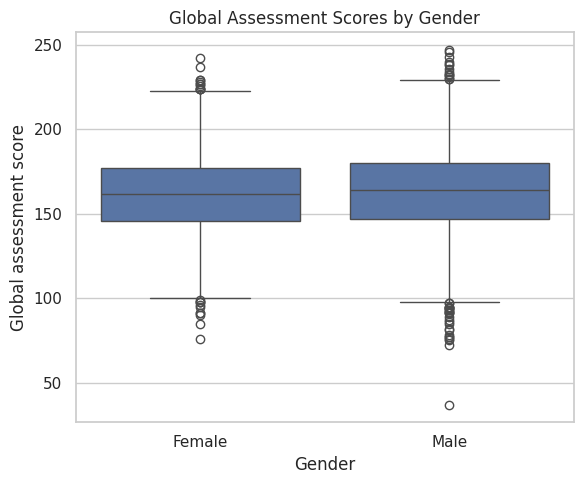

In [ ]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="GENDER", y="G_SC", order=["F", "M"])
plt.xticks([0, 1], ["Female", "Male"])
plt.title("Global Assessment Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Global assessment score")
plt.tight_layout()
plt.savefig("gender_boxplot.png", dpi=300)
plt.show()

## 18. Compare professional assessment domains by gender

This table checks whether gender differences have the same direction in every assessment domain.

In [ ]:
professional_scores = ["QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO", "FEP_PRO"]
gender_subjects = df.groupby("GENDER")[professional_scores].mean()
gender_subjects.round(2)

,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO
GENDER,,,,,,
F,71.89,61.34,58.57,66.53,56.62,145.3
M,81.20,62.79,59.61,68.16,51.71,145.6


## 19. Compare academic programs

The table lists programs by their observed mean global score.

In [ ]:
program = df.groupby("ACADEMIC_PROGRAM")["G_SC"].agg(["count", "mean", "median", "std"])
program = program.sort_values("mean", ascending=False)
program.round(2)

,count,mean,median,std
ACADEMIC_PROGRAM,,,,
CHEMICAL ENGINEERING,1000,176.70,177.0,18.69
CATASTRAL ENGINEERING AND GEODESY,78,174.60,176.0,14.95
ELECTRIC ENGINEERING,278,173.99,174.5,19.35
PRODUCTION ENGINEERING,60,172.90,176.5,20.56
TOPOGRAPHIC ENGINEERY,42,172.71,174.0,15.76
CONTROL ENGINEERING,20,172.15,170.0,20.91
TEXTILE ENGINEERING,1,171.00,171.0,NaN
TRANSPORTATION AND ROAD ENGINEERING,27,167.74,170.0,10.46
ELECTRONIC ENGINEERING,849,166.87,167.0,22.20


## 20. Explore prior achievement and global scores

Pearson correlations describe linear associations between secondary-school scores and later global scores. The heatmap displays the direction and strength of these associations. Correlation does not establish causation, and the two testing stages should not be subtracted to measure progress without confirming scale comparability.

,G_SC
MAT_S11,0.644
CR_S11,0.654
CC_S11,0.635
BIO_S11,0.667
ENG_S11,0.662
G_SC,1.000


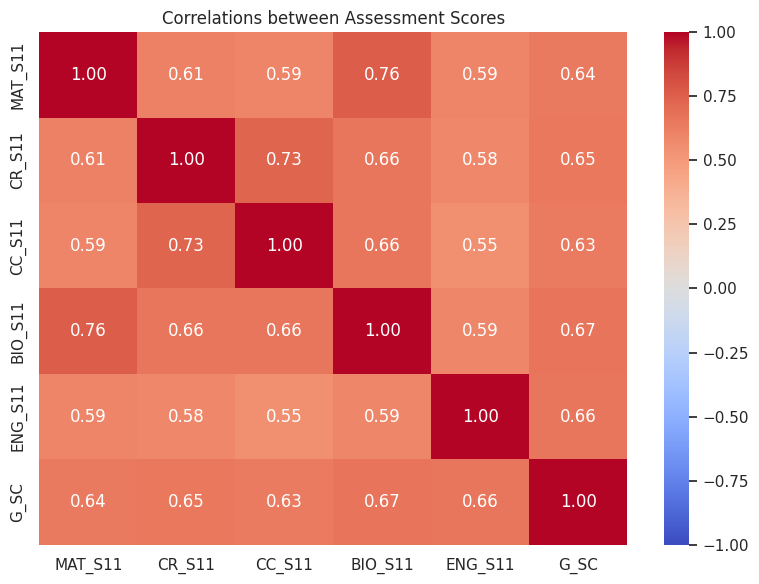

In [ ]:
prior_scores = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11"]
correlations = df[prior_scores + ["G_SC"]].corr()
display(correlations[["G_SC"]].round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlations between Assessment Scores")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

## 21. Plot an example relationship

The scatterplot shows secondary-school mathematics and global scores for individual records. Transparent points reduce overplotting. This chart helps check whether the positive correlation reflects a broader pattern in the data.

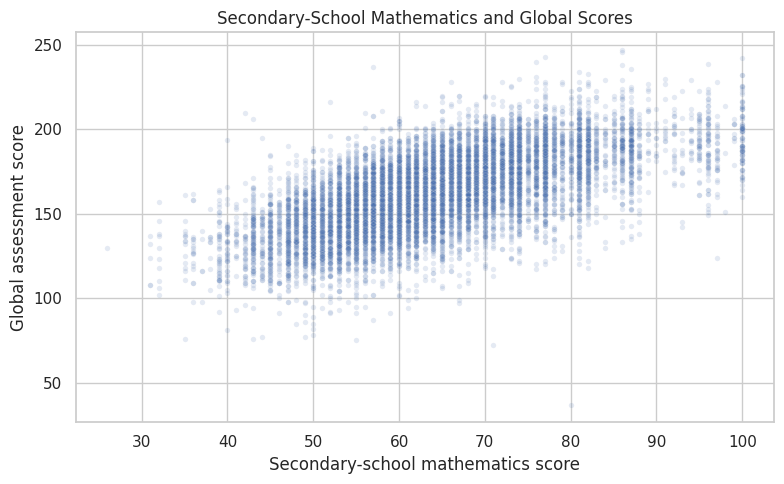

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MAT_S11", y="G_SC", alpha=0.15, s=15)
plt.title("Secondary-School Mathematics and Global Scores")
plt.xlabel("Secondary-school mathematics score")
plt.ylabel("Global assessment score")
plt.tight_layout()
plt.savefig("mathematics_scatterplot.png", dpi=300)
plt.show()

## 22. Summarize all assessment scores by category

To cover the assignment's request for numerical summaries by category, this cell summarizes every assessment score for each main grouping variable. The results are saved as CSV tables for the appendix. The loop simply repeats the same groupby calculation; it does not introduce a new statistical method.

In [ ]:
for column in groups:
    table = df.groupby(column)[scores].agg(["count", "mean", "median", "std"])
    table.to_csv("scores_by_" + column + ".csv")
    print("Saved:", "scores_by_" + column + ".csv")

Saved: scores_by_GENDER.csv
Saved: scores_by_EDU_FATHER.csv
Saved: scores_by_EDU_MOTHER.csv
Saved: scores_by_STRATUM.csv
Saved: scores_by_SISBEN.csv
Saved: scores_by_ACADEMIC_PROGRAM.csv


## 23. Describe ranks and socioeconomic codes separately

Percentile describes relative standing, while quartile and socioeconomic-level codes represent categories or ordered levels. This cell summarizes percentile and counts the coded levels separately from the assessment-score summaries. No undocumented interpretation is assigned to the codes.

In [ ]:
display(df["PERCENTILE"].describe().round(2))

for column in ["2ND_DECILE", "QUARTILE", "SEL", "SEL_IHE"]:
    print(column)
    print(df[column].value_counts().sort_index())

,PERCENTILE
count,12411.00
mean,68.45
std,25.87
min,1.00
25%,51.00
50%,75.00
75%,90.00
max,100.00


2ND_DECILE
2ND_DECILE
1     757
2    1325
3    1944
4    2938
5    5447
Name: count, dtype: int64
QUARTILE
QUARTILE
1    1024
2    1925
3    3145
4    6317
Name: count, dtype: int64
SEL
SEL
1    2138
2    4742
3    1491
4    4040
Name: count, dtype: int64
SEL_IHE
SEL_IHE
1    1137
2    7748
3     834
4    2692
Name: count, dtype: int64


## 24. Check that the group totals agree

Group counts should add up to the number of non-missing global scores. The count-weighted group mean should match the overall mean. These basic checks help identify omitted categories but do not replace the duplicate-ID investigation or other data-quality checks.

In [ ]:
print("Overall count:", df["G_SC"].count())
print("Overall mean:", round(df["G_SC"].mean(), 6))

for column in ["GENDER", "STRATUM", "EDU_FATHER", "EDU_MOTHER"]:
    check = df.groupby(column)["G_SC"].agg(["count", "mean"])
    weighted_mean = (check["count"] * check["mean"]).sum() / check["count"].sum()
    print(column, "count:", check["count"].sum(),
          "weighted mean:", round(weighted_mean, 6))

Overall count: 12411
Overall mean: 162.710499
GENDER count: 12411 weighted mean: 162.710499
STRATUM count: 12411 weighted mean: 162.710499
EDU_FATHER count: 12411 weighted mean: 162.710499
EDU_MOTHER count: 12411 weighted mean: 162.710499


## 25. Save the working data and main summary tables

This cell saves the working data and key tables for Word and SPSS. To download any generated CSV or PNG, open the Files panel on the left of Colab and use the file's download option. The final line downloads the working data directly. Keep the original Excel workbook and save this notebook separately.

In [ ]:
df.to_csv("academic_performance_working.csv", index=False, encoding="utf-8-sig")
overall.to_csv("overall_statistics.csv")
father.to_csv("father_education_summary.csv")
mother.to_csv("mother_education_summary.csv")
stratum.to_csv("stratum_summary.csv")
gender.to_csv("gender_summary.csv")
program.to_csv("program_summary.csv")

files.download("academic_performance_working.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>